# Feature engineering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/02-data-preparation/feature-engineering/feature-engineering-notebook.ipynb)

Companion notebook for the *Feature engineering* slides. Each idea is written first by
hand with NumPy and then with the scikit-learn tool that does the same job.

**Data:** the Adult census income data (does a person earn more than 50K a year?),
a sample of 5 000 people. Rows with missing values are dropped; the *Data cleaning*
notebook shows how to fill them instead.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import preprocessing
from sklearn.compose import make_column_transformer
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42
SAMPLE_SIZE = 5_000
BIN_COUNT = 5

adult = fetch_openml("adult", version=2, as_frame=True, parser="auto").frame
adult = adult.dropna().sample(SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
adult[["age", "workclass", "education", "hours-per-week", "capital-gain", "class"]].head()

,age,workclass,education,hours-per-week,capital-gain,class
0,19,Self-emp-not-inc,10th,40,0,<=50K
1,45,Private,HS-grad,40,0,<=50K
2,47,Private,Assoc-voc,40,0,>50K
3,23,Private,Some-college,40,0,<=50K
4,53,Local-gov,HS-grad,40,0,<=50K


## 1. One-hot encoding

A category $x$ with values $c_1, \dots, c_K$ becomes the vector
$\mathbf{e}(x) = (\mathbb{I}(x = c_1), \dots, \mathbb{I}(x = c_K))$: one 1 and $K-1$ zeros.

In [2]:
class OneHotEncoder:
    """Turn each category column into one 0/1 column per category seen in fit."""

    def fit(self, X):
        self.categories_ = [np.unique(column) for column in X.T]
        return self

    def transform(self, X):
        return np.hstack([(X[:, [j]] == categories).astype(float) for j, categories in enumerate(self.categories_)])

    def fit_transform(self, X):
        return self.fit(X).transform(X)


workclass = adult[["workclass"]].astype(str).to_numpy()
encoder = OneHotEncoder()
one_hot_by_hand = encoder.fit_transform(workclass)
print(encoder.categories_[0])
print(one_hot_by_hand[:3])

['Federal-gov' 'Local-gov' 'Private' 'Self-emp-inc' 'Self-emp-not-inc'
 'State-gov' 'Without-pay']
[[0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]]


In [3]:
one_hot_library = preprocessing.OneHotEncoder(sparse_output=False).fit_transform(workclass)
print("same result:", np.array_equal(one_hot_by_hand, one_hot_library))

same result: True


## 2. Ordinal encoding

When the categories have an order $c_1 < c_2 < \dots < c_K$, category $c_k$ becomes the single number $k - 1$.

In [4]:
class OrdinalEncoder:
    """Replace each category by its position in the given (or sorted) list of categories."""

    def __init__(self, categories="auto"):
        self.categories = categories

    def fit(self, X):
        given = self.categories != "auto"
        self.categories_ = [np.array(self.categories[j]) if given else np.unique(column) for j, column in enumerate(X.T)]
        return self

    def transform(self, X):
        return np.column_stack([(X[:, [j]] == categories).argmax(axis=1) for j, categories in enumerate(self.categories_)])

    def fit_transform(self, X):
        return self.fit(X).transform(X)


education_order = ["Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th",
                   "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors",
                   "Masters", "Prof-school", "Doctorate"]
education = adult[["education"]].astype(str).to_numpy()
education_by_hand = OrdinalEncoder(categories=[education_order]).fit_transform(education)

In [5]:
education_library = preprocessing.OrdinalEncoder(categories=[education_order]).fit_transform(education)
print("same result:", np.array_equal(education_by_hand, education_library))

same result: True


## 3. Binning

Equal-width bins on $[a, b]$: width $w = (b - a)/B$ and $\text{bin}(x) = \lfloor (x - a)/w \rfloor$
(the largest value goes in the last bin).

In [6]:
class KBinsDiscretizer:
    """Cut each feature into equal-width bins between the minimum and maximum seen in fit."""

    def __init__(self, n_bins=5):
        self.n_bins = n_bins

    def fit(self, X):
        self.bin_edges_ = np.linspace(X.min(axis=0), X.max(axis=0), self.n_bins + 1).T
        return self

    def transform(self, X):
        low, high = self.bin_edges_[:, 0], self.bin_edges_[:, -1]
        width = (high - low) / self.n_bins
        return np.clip(np.floor((X - low) / width), 0, self.n_bins - 1)

    def fit_transform(self, X):
        return self.fit(X).transform(X)


ages = adult[["age"]].to_numpy(dtype=float)
binner = KBinsDiscretizer(n_bins=BIN_COUNT)
bins_by_hand = binner.fit_transform(ages)
print("bin edges:", binner.bin_edges_[0])

bin edges: [17.  31.6 46.2 60.8 75.4 90. ]


In [7]:
bins_library = preprocessing.KBinsDiscretizer(n_bins=BIN_COUNT, encode="ordinal", strategy="uniform").fit_transform(ages)
print("same result:", np.array_equal(bins_by_hand, bins_library))

same result: True


## 4. Log transform

`capital-gain` is zero for most people and huge for a few. $\log(1 + x)$ pulls in the long tail.

same result: True


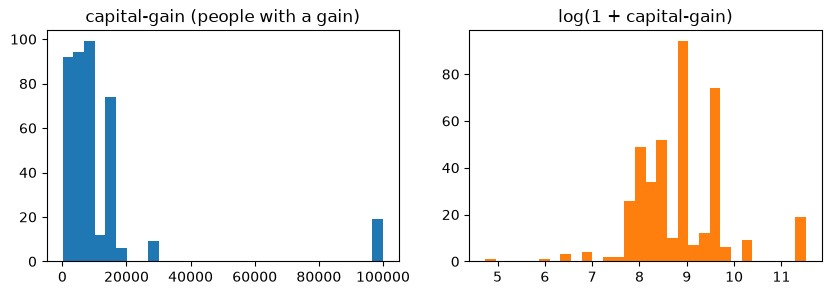

In [8]:
gains = adult["capital-gain"].to_numpy(dtype=float)
log_gains_by_hand = np.log(1 + gains)
log_gains_library = preprocessing.FunctionTransformer(np.log1p).fit_transform(gains.reshape(-1, 1)).ravel()
print("same result:", np.allclose(log_gains_by_hand, log_gains_library))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3))
left.hist(gains[gains > 0], bins=30)
left.set_title("capital-gain (people with a gain)")
right.hist(log_gains_by_hand[gains > 0], bins=30, color="tab:orange")
right.set_title("log(1 + capital-gain)")
plt.show()

## 5. Squares and products

New columns from old ones: $x_1^2$, $x_1 x_2$ and $x_2^2$ let a linear model follow curves and interactions.

In [9]:
class PolynomialFeatures:
    """Add every square and every product of two columns (degree 2)."""

    def fit(self, X):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        columns = range(self.n_features_in_)
        return np.column_stack([X] + [X[:, a] * X[:, b] for a in columns for b in columns if a <= b])

    def fit_transform(self, X):
        return self.fit(X).transform(X)


age_hours = adult[["age", "hours-per-week"]].to_numpy(dtype=float)
squares_by_hand = PolynomialFeatures().fit_transform(age_hours)

In [10]:
squares_library = preprocessing.PolynomialFeatures(degree=2, include_bias=False).fit_transform(age_hours)
print("same result:", np.allclose(squares_by_hand, squares_library))

same result: True


## 6. Does it help?

Compare a model on the raw numeric columns with one that also gets one-hot categories.

In [11]:
numeric = ["age", "hours-per-week", "capital-gain", "capital-loss"]
categorical = ["workclass", "education", "marital-status", "occupation"]
target = adult["class"] == ">50K"
model = LogisticRegression(max_iter=1000)

numeric_only = make_pipeline(preprocessing.StandardScaler(), model)
with_categories = make_pipeline(
    make_column_transformer((preprocessing.StandardScaler(), numeric),
                            (preprocessing.OneHotEncoder(handle_unknown="ignore"), categorical)),
    model)

for name, pipeline, columns in [("numeric only", numeric_only, numeric),
                                ("numeric + one-hot", with_categories, numeric + categorical)]:
    accuracy = cross_val_score(pipeline, adult[columns], target, cv=5).mean()
    print(f"{name:18} accuracy {accuracy:.3f}")

numeric only       accuracy 0.797
numeric + one-hot  accuracy 0.858


## Exercises

1. Build quantile bins for `age` with `np.quantile` and compare with `preprocessing.KBinsDiscretizer(strategy="quantile")`.
2. Add the log of `capital-gain` to the model of section 6. Does the accuracy change?
3. Group the countries in `native-country` that appear fewer than 50 times into one value `"Other"`.